# My First Neural Network — Breast Cancer Classification

**Task:** Build Dense(16, relu) → Dense(8, relu) → Dense(1, sigmoid), use Adam and binary cross-entropy, train for 30 epochs, report test accuracy, and plot training vs validation loss.


## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)

## 2. Load the dataset

In [2]:
df = pd.read_csv("data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
df.shape

(569, 33)

In [4]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

## 3. Remove unnecessary columns

In [5]:
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
df.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df = df.dropna()
df = df.drop_duplicates()
df.shape

(569, 31)

There are no missing measurement values or duplicate rows after dropping the unnecessary columns. All 569 rows remain. We retain valid extreme measurements; no IQR filtering is required for this assignment.

## 4. Encode the target

In [9]:
df["diagnosis"].value_counts()

,count
diagnosis,
B,357
M,212


In [10]:
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 5. Separate features and target

In [11]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]
X.shape

(569, 30)

## 6. Split the data

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20,
    random_state=42, stratify=y_train
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

Training rows: 364
Validation rows: 91
Testing rows: 114


## 7. Scale the features

In [13]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_val = sc.transform(X_val)
X_test = sc.transform(X_test)

## 8. Build the exact ANN

In [14]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Compile the model

In [15]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## 10. Train for 30 epochs

In [16]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    verbose=2
)

Epoch 1/30
12/12 - 2s - 127ms/step - accuracy: 0.6044 - loss: 0.6717 - val_accuracy: 0.6923 - val_loss: 0.6074
Epoch 2/30
12/12 - 0s - 14ms/step - accuracy: 0.7390 - loss: 0.5594 - val_accuracy: 0.8022 - val_loss: 0.5136
Epoch 3/30
12/12 - 0s - 15ms/step - accuracy: 0.8049 - loss: 0.4819 - val_accuracy: 0.8901 - val_loss: 0.4454
Epoch 4/30
12/12 - 0s - 14ms/step - accuracy: 0.8736 - loss: 0.4209 - val_accuracy: 0.9231 - val_loss: 0.3914
Epoch 5/30
12/12 - 0s - 14ms/step - accuracy: 0.9011 - loss: 0.3686 - val_accuracy: 0.9451 - val_loss: 0.3459
Epoch 6/30
12/12 - 0s - 14ms/step - accuracy: 0.9313 - loss: 0.3220 - val_accuracy: 0.9560 - val_loss: 0.3063
Epoch 7/30
12/12 - 0s - 14ms/step - accuracy: 0.9478 - loss: 0.2815 - val_accuracy: 0.9560 - val_loss: 0.2722
Epoch 8/30
12/12 - 0s - 13ms/step - accuracy: 0.9505 - loss: 0.2462 - val_accuracy: 0.9670 - val_loss: 0.2434
Epoch 9/30
12/12 - 0s - 16ms/step - accuracy: 0.9505 - loss: 0.2168 - val_accuracy: 0.9780 - val_loss: 0.2173
Epoch 10/

## 11. Evaluate on the test set

In [17]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", round(test_accuracy * 100, 2))

Test Loss: 0.09368952363729477
Test Accuracy: 0.9736841917037964
Test Accuracy (%): 97.37


## 12. Plot training vs validation loss

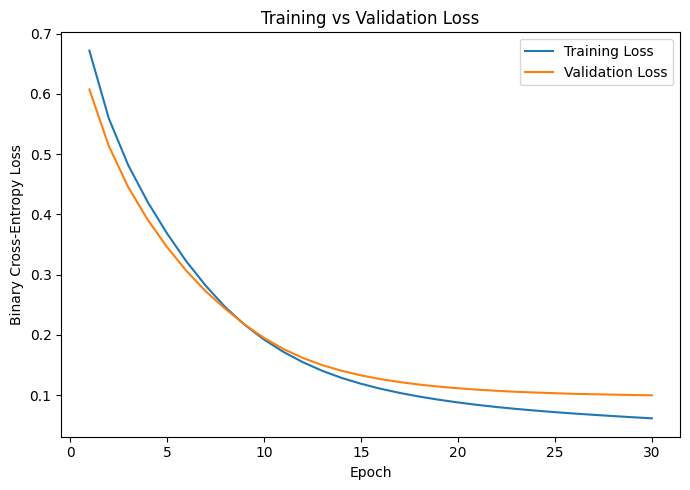

In [18]:
plt.figure(figsize=(7, 5))
plt.plot(range(1, 31), history.history["loss"], label="Training Loss")
plt.plot(range(1, 31), history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Forward propagation and backpropagation

During forward propagation, each training batch passes through the 16-unit and 8-unit hidden layers to produce a probability, and the loss measures how far the predictions are from the correct labels. Backpropagation works backward through the network to calculate how each weight contributed to the loss, and Adam uses these gradients to update the weights after each batch. This repeats across the training batches in every epoch, while validation loss is measured without updating weights.


## Result summary

The ANN achieved 97.37% test accuracy (111 correct predictions out of 114) after 30 epochs. The test set was kept separate from both training and validation, and scaling was fitted only on training rows. This is a classroom classification result on one split, not evidence of clinical readiness; results may vary across TensorFlow versions or hardware.